# Exercise 53 – Training, validation and test sets with early stopping

**Week 10 · Training neural networks**

The data are split into three sets:

* **training** – used to update the weights,
* **validation** – monitored during training; when its loss stops improving
  we stop (*early stopping*),
* **test** – only used once at the end to estimate how well the model
  generalises.

Mini-batches are served by `torch.utils.data.DataLoader`.

In [1]:
import matplotlib.pyplot as plt
import torch
from torch.utils.data import DataLoader, TensorDataset

from comphy.models import MLP
from comphy.plotting import plot_loss_history, setup_axes
from comphy.training import evaluate, train

torch.manual_seed(0)

x_train = torch.tensor([-2.5185, 3.7913, -4.7294, 5.8313, -5.1949, -1.8359, 2.5770, -8.7352,
                        7.7236, -6.6444, -0.1604, -8.2950, -0.8292, -5.7322, -8.0877, 3.2723,
                        3.7528, 4.6493, -4.1721, 6.4619, 3.5825, 5.7389, -2.8990, -4.9992,
                        -3.8179, 0.8487, 5.4030, -0.3305, -1.6794, -8.2903, -5.6771, 8.1123,
                        -5.6671, -4.1416, -5.7792, 5.6271, 3.0327, -1.4105, 1.2440, 6.1406])
y_train = torch.tensor([5.3765, 8.0848, -3.1590, 4.8315, -1.5031, 2.8388, 5.5292, -8.6496,
                        0.1439, -6.5176, 7.8955, -5.3279, 0.9723, -4.8308, -7.4774, 4.0248,
                        6.7662, 2.7932, 0.8295, 2.4870, 5.7717, 3.3586, 0.6717, -1.7881,
                        -0.5134, 6.9941, 7.7333, 4.5161, 3.7155, -9.2325, 0.7633, -3.4318,
                        -2.8717, -2.8029, -3.2103, 3.0772, 6.6173, 2.6258, 9.3260, 3.2308])
x_val = torch.tensor([-8.0973, -7.9917, -0.1596, 8.4471, 7.3714])
y_val = torch.tensor([-7.7651, -4.7321, 7.7455, -0.8433, 2.6792])
x_test = torch.tensor([-8.9859, -0.1808, -2.3172, 6.6878, 6.2361])
y_test = torch.tensor([-8.4506, 2.8572, 4.1936, 2.7723, 1.0726])

train_loader = DataLoader(TensorDataset(x_train, y_train), batch_size=20, shuffle=True)
val_loader = DataLoader(TensorDataset(x_val, y_val), batch_size=20)
test_loader = DataLoader(TensorDataset(x_test, y_test), batch_size=20)

print(f"{len(train_loader.dataset)} training, {len(val_loader.dataset)} validation, "
      f"{len(test_loader.dataset)} test points")
print(f"batches per epoch: {len(train_loader)}")

40 training, 5 validation, 5 test points
batches per epoch: 2


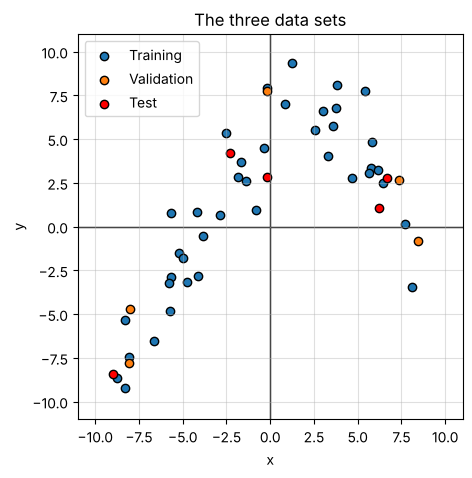

In [2]:
SETS = [("Training", x_train, y_train, "C0"), ("Validation", x_val, y_val, "C1"),
        ("Test", x_test, y_test, "red")]

fig, ax = plt.subplots(figsize=(5, 5))
for name, x, y, color in SETS:
    ax.scatter(x, y, color=color, label=name, edgecolor="black")
setup_axes(ax, xlim=(-11, 11), ylim=(-11, 11), title="The three data sets", equal=True)
ax.legend()
plt.show()

## Training with early stopping (patience 30)

In [3]:
model = MLP(hidden=(8, 8, 8), activation="silu")
history = train(model, train_loader, val_loader, epochs=1000, lr=0.01, patience=30)
test_loss = evaluate(model, test_loader)
print(f"test loss: {test_loss:.3f}")

Early stopping at epoch 234
test loss: 3.846


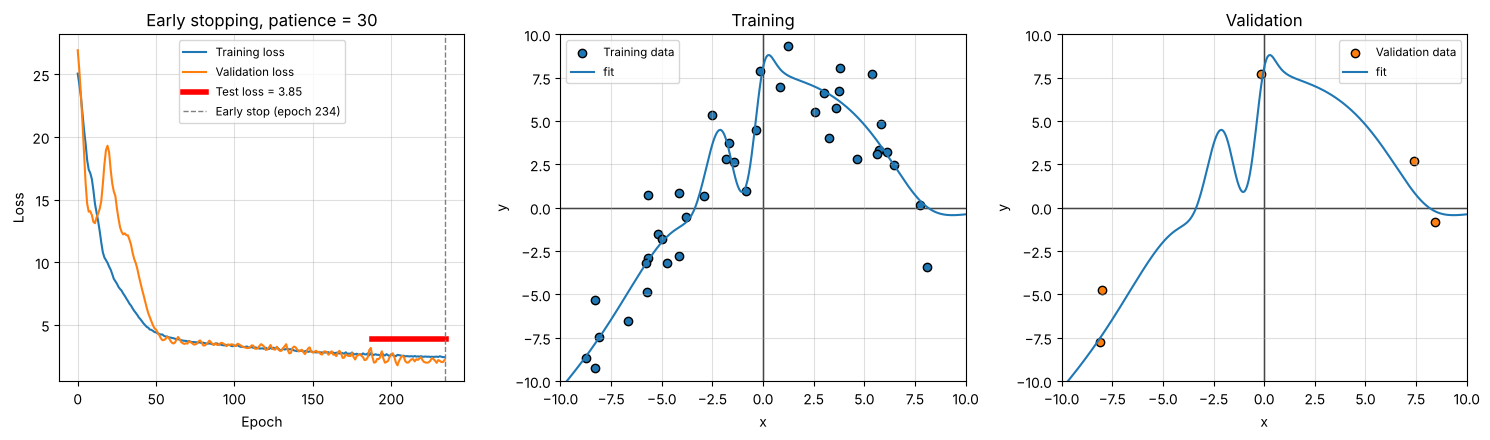

In [4]:
xs = torch.linspace(-10, 10, 300)
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
plot_loss_history(axes[0], history, test_loss=test_loss, title="Early stopping, patience = 30")
for ax, (name, x, y, color) in zip(axes[1:], SETS[:2]):
    ax.scatter(x, y, color=color, edgecolor="black", label=f"{name} data")
    with torch.no_grad():
        ax.plot(xs, model(xs), color="C0", label="fit")
    setup_axes(ax, xlim=(-10, 10), ylim=(-10, 10), title=name)
    ax.legend(fontsize="small")
fig.tight_layout()
plt.show()